In [2]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

URL = ('https://raw.githubusercontent.com/carmengg/eds220-hwk-1/main/data/earthquake_data.csv')

data = pd.read_csv(URL)
data2 = gpd.read_file("data/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp")


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120108 entries, 0 to 120107
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   time       120108 non-null  object 
 1   latitude   120108 non-null  float64
 2   longitude  120108 non-null  float64
 3   depth      120107 non-null  float64
 4   mag        120065 non-null  float64
 5   id         120108 non-null  object 
 6   place      120108 non-null  object 
 7   type       120108 non-null  object 
dtypes: float64(4), object(4)
memory usage: 7.3+ MB


In [4]:
data2.head()

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180.00000 -16.06713, 180.00000..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95000, 34.07262 -1.05982..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84000 49.00000, -122.9742..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84000 49.00000, -120.0000..."


In [5]:
filtered = data[data['mag'] >= 6.5]
print(filtered.min())

time                  2014-01-01 16:03:29.000
latitude                             -55.4703
longitude                           -178.4001
depth                                     4.0
mag                                       6.5
id                                 nc72182046
place        106km WSW of Sangay, Philippines
type                               earthquake
dtype: object


In [6]:
points = gpd.points_from_xy(filtered['longitude'], filtered['latitude'])

geodf = gpd.GeoDataFrame(filtered, geometry = points, crs = 'EPSG:4326')

Text(0.5, 88.64025169067803, 'Latitude')

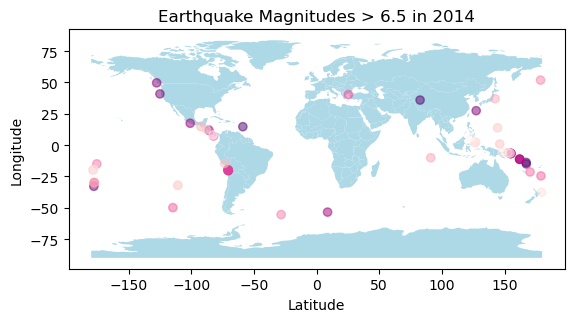

In [16]:
fig, ax = plt.subplots()

data2.plot(ax = ax,
           color = 'lightblue')

geodf.plot(ax= ax,
          alpha = 0.5,
          c = 'mag',
          cmap = 'RdPu_r')

ax.set_title('Earthquake Magnitudes > 6.5 in 2014')
ax.set_ylabel('Longitude')
ax.set_xlabel('Latitude')

